<a href="https://colab.research.google.com/github/uzmaa29/Pneumonia-Detection/blob/main/pnuemonia_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from fastai import *
from fastai.vision.all import *
from fastai.metrics import error_rate
import pandas as pd
import numpy as np


In [4]:
import os
os.environ['KAGGLE_CONFIG_DIR'] = '/content'

In [5]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [01:53<00:00, 21.8MB/s]



In [6]:
!unzip /content/chest-xray-pneumonia.zip -d /content/chest_xray

Streaming output truncated to the last 5000 lines.
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0442-0001.jpeg  


In [8]:
path = '/content/chest_xray/chest_xray'

In [10]:
data = ImageDataLoaders.from_folder(
    path,
    train = '.',
    valid_pct= 0.2,
    seed = 67,
    item_tfms= Resize(224)
)

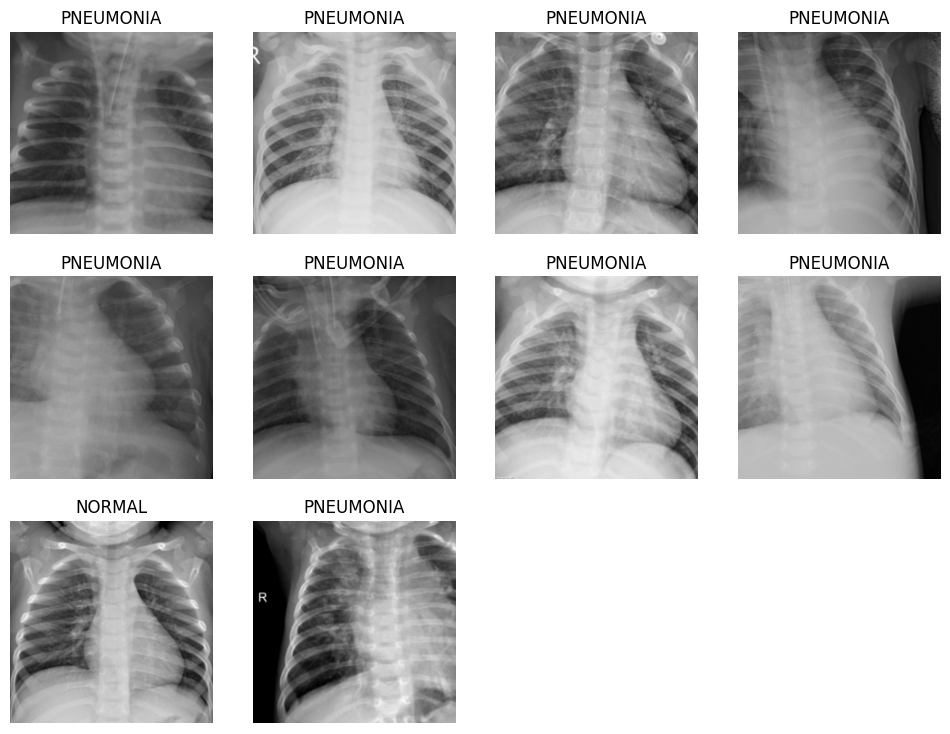

In [14]:
data.show_batch(max_n = 10)

In [15]:
learn = vision_learner(data, models.resnet50, metrics = [accuracy], model_dir=Path('Path'), path = Path("."))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 148MB/s]


<div></div>

SuggestedLRs(valley=0.0008317637839354575)

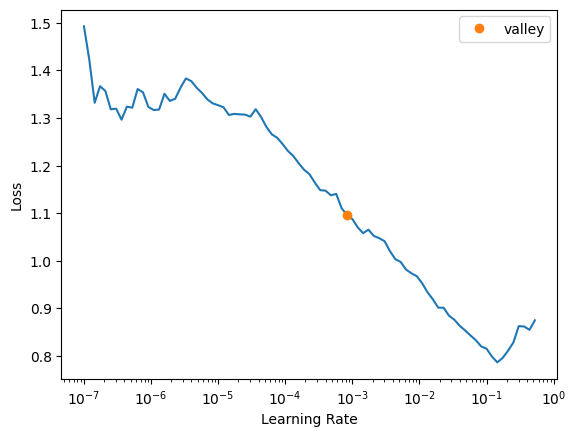

In [16]:
learn.lr_find()

In [18]:
lr1 = 1e-3
lr2 = 1e-1
learn.fit_one_cycle(4, slice(lr1, lr2))

epoch,train_loss,valid_loss,accuracy,time
0,0.560447,0.274235,0.947481,03:52
1,0.269329,0.112660,0.970538,03:52
2,0.161898,0.099686,0.964560,03:48
3,0.078829,0.068235,0.975662,03:48


In [19]:
 interpret = ClassificationInterpretation.from_learner(learn)

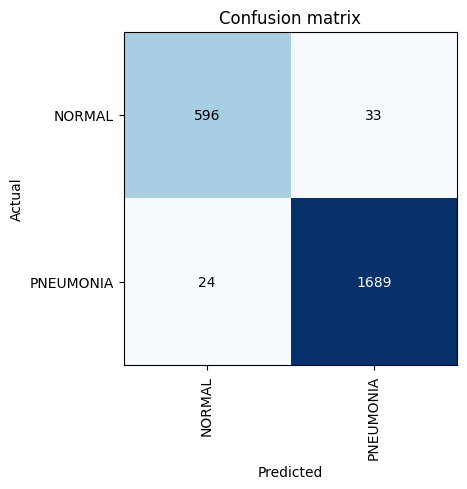

In [20]:
interpret.plot_confusion_matrix()

In [21]:
img = PILImage.create('/content/chest_xray/chest_xray/test/NORMAL/IM-0001-0001.jpeg')

<Axes: >

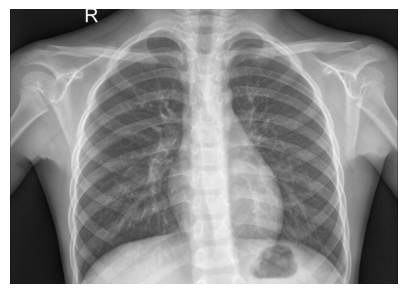

In [22]:
img.show()

In [23]:
print(learn.predict(img)[0])

NORMAL


In [24]:
img = PILImage.create('/content/chest_xray/chest_xray/test/PNEUMONIA/person100_bacteria_482.jpeg')

<Axes: >

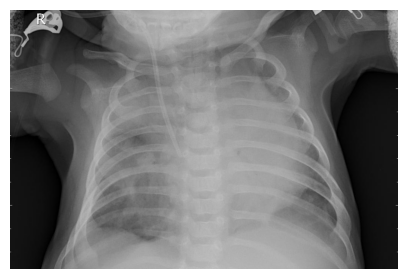

In [25]:
img.show()

In [26]:
print(learn.predict(img)[0])

PNEUMONIA
